
## Ejercicio 1: Métricas sobre columnas numéricas usando arrays de NumPy

**Objetivo:** Calcular métricas estadísticas sobre las columnas numéricas del dataset `online_retail_II.csv` utilizando arrays de NumPy, aplicar filtrado mediante máscaras booleanas, comparar el tiempo de ejecución de un ciclo `for` contra operaciones vectorizadas, y responder a las preguntas teóricas del taller.

---

### 1. Carga el dataset con Pandas y revisa sus columnas y tipos

In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: '%.2f' % x)

dataset_path = 'online_retail_II.csv'
df = pd.read_csv(dataset_path)

print(f"Dimensiones del dataset: {df.shape[0]:,} filas y {df.shape[1]} columnas.\n")
print("Primeras 5 filas:")
display(df.head())

Dimensiones del dataset: 1,067,371 filas y 8 columnas.

Primeras 5 filas:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom


In [2]:
print("Información del DataFrame:")
df.info()

Información del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [3]:
print("Tipos de datos por columna:")
print(df.dtypes)

Tipos de datos por columna:
Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object


---
### 2. Selecciona dos columnas numéricas y conviértelas a arrays con `.to_numpy()`

In [4]:
quantities = df['Quantity'].to_numpy()
prices = df['Price'].to_numpy()

print(f"Array 'quantities': tipo={type(quantities)}, dtype={quantities.dtype}, tamaño={quantities.size:,}")
print(f"Primeros 10 elementos de 'quantities': {quantities[:10]}\n")

print(f"Array 'prices': tipo={type(prices)}, dtype={prices.dtype}, tamaño={prices.size:,}")
print(f"Primeros 10 elementos de 'prices': {prices[:10]}")

Array 'quantities': tipo=<class 'numpy.ndarray'>, dtype=int64, tamaño=1,067,371
Primeros 10 elementos de 'quantities': [12 12 12 48 24 24 24 10 12 12]

Array 'prices': tipo=<class 'numpy.ndarray'>, dtype=float64, tamaño=1,067,371
Primeros 10 elementos de 'prices': [6.95 6.75 6.75 2.1  1.25 1.65 1.25 5.95 2.55 3.75]


---
### 3. Calcula con NumPy: suma, media, mediana, máximo, mínimo y desviación estándar

In [5]:
suma_qty = np.sum(quantities)
media_qty = np.mean(quantities)
mediana_qty = np.median(quantities)
max_qty = np.max(quantities)
min_qty = np.min(quantities)
std_qty = np.std(quantities)

suma_price = np.sum(prices)
media_price = np.mean(prices)
mediana_price = np.median(prices)
max_price = np.max(prices)
min_price = np.min(prices)
std_price = np.std(prices)

metrics_df = pd.DataFrame({
    'Métrica': ['Suma total', 'Media (Promedio)', 'Mediana', 'Máximo', 'Mínimo', 'Desviación estándar'],
    'Quantity': [f"{suma_qty:,.2f}", f"{media_qty:.2f}", f"{mediana_qty:.2f}", f"{max_qty:,.2f}", f"{min_qty:,.2f}", f"{std_qty:.2f}"],
    'Price': [f"{suma_price:,.2f}", f"{media_price:.2f}", f"{mediana_price:.2f}", f"{max_price:,.2f}", f"{min_price:,.2f}", f"{std_price:.2f}"]
})

print("Resumen de Métricas Estadísticas (NumPy):")
display(metrics_df)

Resumen de Métricas Estadísticas (NumPy):


,Métrica,Quantity,Price
0,Suma total,"10,608,492.00","4,962,621.63"
1,Media (Promedio),9.94,4.65
2,Mediana,3.00,2.10
3,Máximo,"80,995.00","38,970.00"
4,Mínimo,"-80,995.00","-53,594.36"
5,Desviación estándar,172.71,123.55


---
### 4. Filtra con una máscara booleana (valores mayores que la media) y cuenta cuántos quedan

In [6]:
mask_qty = quantities > media_qty
filtered_qty = quantities[mask_qty]
total_qty_above = len(filtered_qty)
pct_qty_above = (total_qty_above / len(quantities)) * 100

mask_price = prices > media_price
filtered_price = prices[mask_price]
total_price_above = len(filtered_price)
pct_price_above = (total_price_above / len(prices)) * 100

print(f"Total registros analizados: {len(quantities):,}\n")

print(f"Columna 'Quantity':")
print(f" - Media calculada: {media_qty:.2f}")
print(f" - Registros con Quantity > media: {total_qty_above:,} ({pct_qty_above:.2f}%)")
print(f" - Muestra de 10 valores filtrados: {filtered_qty[:10]}\n")

print(f"Columna 'Price':")
print(f" - Media calculada: {media_price:.2f}")
print(f" - Registros con Price > media: {total_price_above:,} ({pct_price_above:.2f}%)")
print(f" - Muestra de 10 valores filtrados: {filtered_price[:10]}")

Total registros analizados: 1,067,371

Columna 'Quantity':
 - Media calculada: 9.94
 - Registros con Quantity > media: 301,861 (28.28%)
 - Muestra de 10 valores filtrados: [12 12 12 48 24 24 24 10 12 12]

Columna 'Price':
 - Media calculada: 4.65
 - Registros con Price > media: 230,607 (21.61%)
 - Muestra de 10 valores filtrados: [6.95 6.75 6.75 5.95 5.95 5.45 5.95 6.95 8.5  4.65]


---
### 5. Compara el tiempo de un ciclo for contra la operación vectorizada

In [7]:
t0 = time.perf_counter()
suma_for = 0
for x in quantities:
    suma_for += x
t_for_sum = time.perf_counter() - t0

t0 = time.perf_counter()
suma_vec = np.sum(quantities)
t_vec_sum = time.perf_counter() - t0

speedup_sum = t_for_sum / t_vec_sum

print(f"--- Prueba 1: Suma sobre {len(quantities):,} datos ---")
print(f"Tiempo Ciclo For:          {t_for_sum:.6f} segundos")
print(f"Tiempo NumPy Vectorizado: {t_vec_sum:.6f} segundos")
print(f"Aceleración: {speedup_sum:.1f}x más rápido con NumPy\n")

t0 = time.perf_counter()
filtered_for = []
for x in quantities:
    if x > media_qty:
        filtered_for.append(x)
t_for_filt = time.perf_counter() - t0

t0 = time.perf_counter()
filtered_vec = quantities[quantities > media_qty]
t_vec_filt = time.perf_counter() - t0

speedup_filt = t_for_filt / t_vec_filt

print(f"--- Prueba 2: Filtrado sobre {len(quantities):,} datos ---")
print(f"Tiempo Ciclo For:          {t_for_filt:.6f} segundos")
print(f"Tiempo NumPy Vectorizado: {t_vec_filt:.6f} segundos")
print(f"Aceleración: {speedup_filt:.1f}x más rápido con NumPy")

--- Prueba 1: Suma sobre 1,067,371 datos ---
Tiempo Ciclo For:          0.350019 segundos
Tiempo NumPy Vectorizado: 0.000976 segundos
Aceleración: 358.5x más rápido con NumPy

--- Prueba 2: Filtrado sobre 1,067,371 datos ---
Tiempo Ciclo For:          0.445699 segundos
Tiempo NumPy Vectorizado: 0.007979 segundos
Aceleración: 55.9x más rápido con NumPy


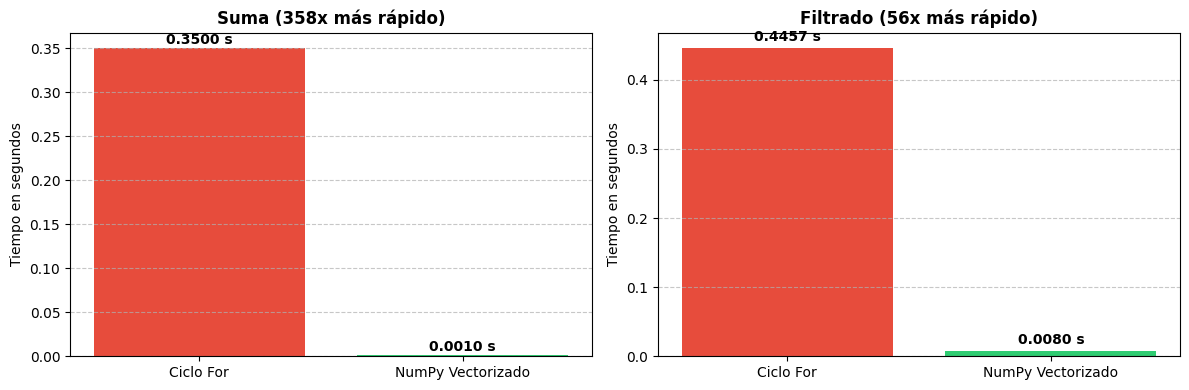

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Ciclo For', 'NumPy Vectorizado'], [t_for_sum, t_vec_sum], color=['#e74c3c', '#2ecc71'])
axes[0].set_title(f'Suma ({speedup_sum:.0f}x más rápido)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tiempo en segundos')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate([t_for_sum, t_vec_sum]):
    axes[0].text(i, v + 0.005, f"{v:.4f} s", ha='center', fontweight='bold')

axes[1].bar(['Ciclo For', 'NumPy Vectorizado'], [t_for_filt, t_vec_filt], color=['#e74c3c', '#2ecc71'])
axes[1].set_title(f'Filtrado ({speedup_filt:.0f}x más rápido)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Tiempo en segundos')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate([t_for_filt, t_vec_filt]):
    axes[1].text(i, v + 0.01, f"{v:.4f} s", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()